# Inferencia sobre `test.csv`

**Proyecto #2 · Notebook 4 de 4** · Maestría · 4T 2026 · Product Management · Clase Cloud
**Autor:** Danny García

---

Este notebook carga el pipeline completo del notebook 04 y lo usa para predecir las ventas de
**noviembre de 2015** (mes 34), un mes que el modelo no ha visto nunca.

## La regla de este notebook: ni un solo `fit`

Aquí solo se **aplica** lo aprendido. Si en algún punto hiciera falta volver a ajustar algo, o
repetir un cálculo del notebook 02 o 03, significaría que el artefacto está incompleto: la lógica
viviría a medias dentro del `.pkl` y a medias en el código del notebook, y cualquier diferencia
entre ambos produciría predicciones equivocadas sin ninguna señal de alarma.

Que este notebook sea corto es la prueba de que el pipeline está bien construido.

## Qué entra y qué sale

| | |
|---|---|
| **Entra** | `data/raw/test.csv` crudo: `ID`, `shop_id`, `item_id` |
| **Artefacto** | `models/pipeline_completo.pkl` |
| **Sale** | `data/processed/submission.csv` con `ID` e `item_cnt_month` |

## Índice

| # | Sección |
|---|---|
| 0 | [Configuración](#0) |
| 1 | [Carga del artefacto](#1) |
| 2 | [Qué trae test que el entrenamiento no tenía](#2) |
| 3 | [Predicción](#3) |
| 4 | [Verificaciones](#4) |
| 5 | [Gráficas de control](#5) |
| 6 | [Archivo de envío](#6) |

<a id="0"></a>
## 0. Configuración

In [1]:
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from predict_future_sales.config import (
    FIGURES_DIR,
    MODELS_DIR,
    PROCESSED_DATA_DIR,
    RAW_DATA_DIR,
)

sklearn.set_config(transform_output="pandas")

AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA2, REJILLA, EJE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": EJE, "axes.labelcolor": TINTA2, "axes.titlecolor": TINTA,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 10, "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
    "xtick.color": TINTA2, "ytick.color": TINTA2,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "figure.dpi": 110, "savefig.bbox": "tight",
    "font.family": "DejaVu Sans",
})
pd.set_option("display.width", 160)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

2026-11-20 07:13:28.139 -06:00 | INFO     | predict_future_sales.config:<module>:11 - PROJ_ROOT path is: C:\Users\dgarc\OneDrive\Escritorio\Maestria\4T_2026\Product_Mang\Clase_Cloud\predict_future_sales


<a id="1"></a>
## 1. Carga del artefacto

In [2]:
RUTA_MODELO = MODELS_DIR / "pipeline_completo.pkl"
t0 = time.time()
pipeline = joblib.load(RUTA_MODELO)
print(f"cargado en {time.time() - t0:.1f} s  ({RUTA_MODELO.stat().st_size / 1e6:.1f} MB)")

print("\nPasos del pipeline:")
for nombre, paso in pipeline.named_steps["caracteristicas"].steps:
    print(f"  caracteristicas / {nombre:<12} {type(paso).__name__}")
print(f"  modelo             {type(pipeline.named_steps['modelo']).__name__}")

cargado en 0.8 s  (8.5 MB)

Pasos del pipeline:
  caracteristicas / catalogos    UnirCatalogos
  caracteristicas / calendario   CaracteristicasCalendario
  caracteristicas / rezagos      LagFeatures
  caracteristicas / mapeos       Mapper
  caracteristicas / a_float32    ReducirPrecision
  caracteristicas / preproceso   ColumnTransformer
  caracteristicas / float32      ReducirPrecision
  modelo             HistGradientBoostingRegressor


In [3]:
test = pd.read_csv(RAW_DATA_DIR / "test.csv", encoding="utf-8")
print(f"test.csv: {test.shape[0]:,} filas x {test.shape[1]} columnas")
print(f"columnas: {list(test.columns)}")
display(test.head())

# El archivo no trae date_block_num: el mes a predecir es el 34 y el pipeline
# lo rellena solo. Es una constante conocida, no un dato que haya que estimar.
print(f"\nmes a predecir: 34 (noviembre de 2015)")
print(f"tiendas: {test.shop_id.nunique()} | productos: {test.item_id.nunique()}")
print(f"rejilla completa 42 x 5100 = {42 * 5100:,}: "
      f"{'si' if 42 * 5100 == len(test) else 'no'}")

test.csv: 214,200 filas x 3 columnas
columnas: ['ID', 'shop_id', 'item_id']


,ID,shop_id,item_id
0,0,5,5037
1,1,5,5320
2,2,5,5233
3,3,5,5232
4,4,5,5268



mes a predecir: 34 (noviembre de 2015)
tiendas: 42 | productos: 5100
rejilla completa 42 x 5100 = 214,200: si


<a id="2"></a>
## 2. Qué trae `test` que el entrenamiento no tenía

Antes de predecir conviene saber a qué se enfrenta el modelo. El EDA del Proyecto #1 ya lo había
medido, pero aquí se confirma sobre los datos reales de inferencia.

In [4]:
sales = pd.read_csv(RAW_DATA_DIR / "sales_train.csv", encoding="utf-8")

pares_train = set(map(tuple, sales[["shop_id", "item_id"]].drop_duplicates().to_numpy()))
pares_test = list(map(tuple, test[["shop_id", "item_id"]].to_numpy()))
ultimo_mes = set(map(tuple, sales.loc[sales.date_block_num == 33,
                                      ["shop_id", "item_id"]].drop_duplicates().to_numpy()))

con_historial = np.array([p in pares_train for p in pares_test])
vivo_mes_33 = np.array([p in ultimo_mes for p in pares_test])

diagnostico = pd.DataFrame([
    ("Con venta en el mes 33 (el anterior)", int(vivo_mes_33.sum())),
    ("Con historial, pero no en el mes 33", int((con_historial & ~vivo_mes_33).sum())),
    ("Sin historial alguno", int((~con_historial).sum())),
], columns=["situacion", "pares"])
diagnostico["%"] = (diagnostico["pares"] / len(test) * 100).round(1)
display(diagnostico.set_index("situacion"))

print(f"productos de test nunca vistos en train: "
      f"{len(set(test.item_id) - set(sales.item_id)):,}")
print(f"tiendas de test ausentes de train      : "
      f"{len(set(test.shop_id) - set(sales.shop_id))}")

,pares,%
situacion,,
Con venta en el mes 33 (el anterior),28680,13.4
"Con historial, pero no en el mes 33",82724,38.6
Sin historial alguno,102796,48.0


productos de test nunca vistos en train: 363
tiendas de test ausentes de train      : 0


**Esto es lo que hace difícil el problema.** Solo una de cada ocho filas tenía actividad el mes
anterior, que es justo la variable más informativa según el notebook 02. Para casi la mitad no
hay ningún historial, y el modelo tiene que apoyarse en lo único que queda: la categoría del
producto, la tienda, la ciudad y el calendario.

Ninguna tienda de `test` es desconocida, así que al menos esa dimensión está cubierta.

<a id="3"></a>
## 3. Predicción

Una sola llamada. El pipeline se encarga de todo: pega los catálogos, deriva el calendario,
calcula los rezagos desde el historial que lleva dentro, aplica los mapeos, imputa, recorta,
transforma, escala y predice.

In [5]:
t0 = time.time()
predicciones = pipeline.predict(test[["shop_id", "item_id"]])
print(f"predicho en {time.time() - t0:.0f} s")
print(f"{len(predicciones):,} predicciones generadas")
print(f"\nantes de recortar: min {predicciones.min():.3f} / "
      f"max {predicciones.max():.3f} / media {predicciones.mean():.3f}")

predicho en 3 s
214,200 predicciones generadas

antes de recortar: min -0.191 / max 21.008 / media 0.203


In [6]:
# El recorte a [0, 20] es la regla de la competencia: los valores reales contra
# los que se evalua ya vienen recortados a ese rango. Ademas, una prediccion
# negativa de unidades vendidas no significa nada.
predicciones = np.clip(predicciones, 0, 20)
print(f"tras recortar    : min {predicciones.min():.3f} / "
      f"max {predicciones.max():.3f} / media {predicciones.mean():.3f}")
print(f"\npredicciones exactamente cero: {(predicciones == 0).mean():.1%}")
print(f"predicciones por debajo de 0.5: {(predicciones < 0.5).mean():.1%}")
display(pd.Series(predicciones).describe().round(4).to_frame("prediccion"))

tras recortar    : min 0.000 / max 20.000 / media 0.204

predicciones exactamente cero: 22.2%
predicciones por debajo de 0.5: 91.2%


,prediccion
count,214200.0000
mean,0.2039
std,0.6785
min,0.0000
25%,0.0017
50%,0.0545
75%,0.1751
max,20.0000


<a id="4"></a>
## 4. Verificaciones

Estas comprobaciones **no verifican que las predicciones sean buenas**, sino que sean *posibles*.
Lo único que respalda la calidad es el RMSE del notebook 04, medido sobre otros meses.

La más importante es la de **alineación**. Una permutación de las filas produce un archivo
perfectamente válido, con cada predicción en la fila equivocada, y el único síntoma es un mal
resultado sin ninguna explicación.

In [7]:
# 1. Tantas predicciones como filas entraron.
assert len(predicciones) == len(test), "El numero de predicciones no coincide"
print(f"1. filas de entrada y de salida ...... {len(test):,} = {len(predicciones):,}  OK")

# 2. Sin nulos ni infinitos.
assert np.isfinite(predicciones).all(), "Hay predicciones nulas o infinitas"
print(f"2. valores finitos ................... {np.isfinite(predicciones).sum():,}  OK")

# 3. Dentro del rango admitido.
assert predicciones.min() >= 0 and predicciones.max() <= 20
print(f"3. rango [0, 20] ..................... "
      f"[{predicciones.min():.2f}, {predicciones.max():.2f}]  OK")

# 4. Alineacion: la prediccion i corresponde al ID i.
envio = pd.DataFrame({"ID": test["ID"].to_numpy(), "item_cnt_month": predicciones})
assert envio["ID"].is_monotonic_increasing, "Los ID no estan en orden"
assert envio["ID"].is_unique, "Hay ID repetidos"
assert envio["ID"].tolist() == test["ID"].tolist(), "Los ID no coinciden con test.csv"
print(f"4. alineacion de ID .................. {len(envio):,} ID unicos y en orden  OK")

# 5. El formato coincide con el que espera la competencia.
muestra_oficial = pd.read_csv(RAW_DATA_DIR / "sample_submission.csv", encoding="utf-8")
assert list(envio.columns) == list(muestra_oficial.columns)
assert len(envio) == len(muestra_oficial)
assert envio["ID"].equals(muestra_oficial["ID"])
print(f"5. formato de envio .................. columnas {list(envio.columns)}  OK")

1. filas de entrada y de salida ...... 214,200 = 214,200  OK
2. valores finitos ................... 214,200  OK
3. rango [0, 20] ..................... [0.00, 20.00]  OK
4. alineacion de ID .................. 214,200 ID unicos y en orden  OK
5. formato de envio .................. columnas ['ID', 'item_cnt_month']  OK


In [8]:
# Comprobacion de coherencia: el modelo deberia predecir MAS para los pares que
# vendieron el mes pasado que para los que no tienen historial. Si no fuera
# asi, algo estaria mal conectado: seria la senial de que los rezagos no
# llegaron al modelo.
resumen = pd.DataFrame({
    "situacion": np.where(vivo_mes_33, "vendio en el mes 33",
                 np.where(con_historial, "con historial, inactivo", "sin historial")),
    "prediccion": predicciones,
}).groupby("situacion")["prediccion"].agg(["count", "mean", "median", "max"]).round(4)
display(resumen)

media_vivos = predicciones[vivo_mes_33].mean()
media_sin = predicciones[~con_historial].mean()
assert media_vivos > media_sin, "El modelo no distingue los pares activos de los inertes"
print(f"media de los activos ({media_vivos:.4f}) > media de los sin historial "
      f"({media_sin:.4f}): OK")
print(f"razon: {media_vivos / max(media_sin, 1e-9):.1f}x")

,count,mean,median,max
situacion,,,,
"con historial, inactivo",82724,0.1791,0.1308,3.6462
sin historial,102796,0.0051,0.0008,0.6938
vendio en el mes 33,28680,0.9879,0.5311,20.0000


media de los activos (0.9879) > media de los sin historial (0.0051): OK
razon: 191.9x


<a id="5"></a>
## 5. Gráficas de control

Comparar la distribución de lo predicho con la de lo observado no demuestra que la predicción sea
correcta, pero sí detecta desastres: una predicción concentrada en un solo valor, o con una forma
que no se parece en nada a la realidad, indica que algo se rompió.

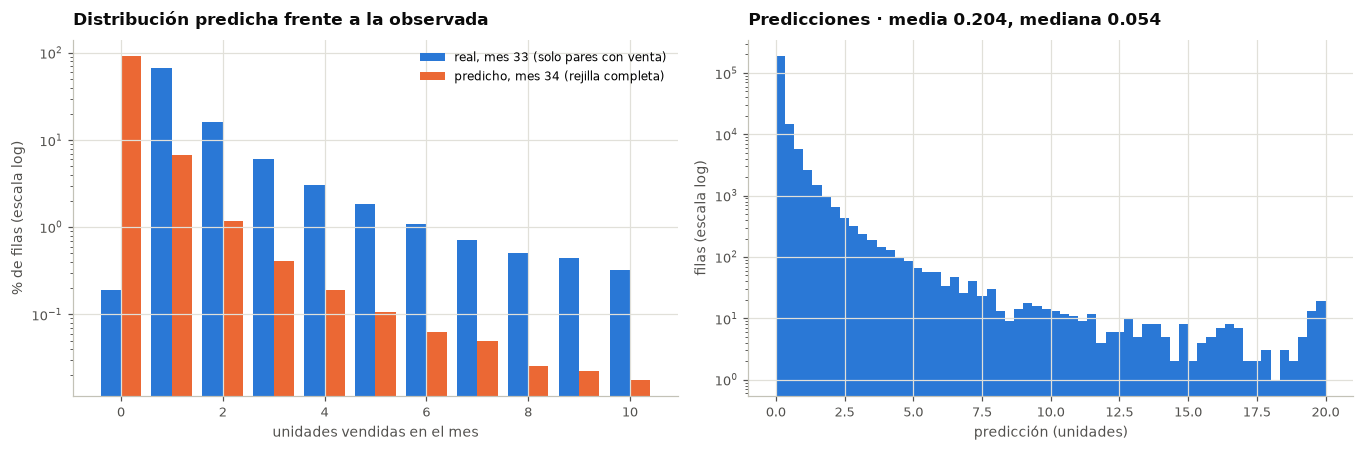

In [9]:
# Distribucion real del ultimo mes observado, para comparar.
real_33 = (sales[sales.date_block_num == 33]
           .groupby(["shop_id", "item_id"], observed=True)["item_cnt_day"].sum()
           .clip(0, 20))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.2))

topes = np.arange(0, 11)
a1.bar(topes - 0.2, [((real_33 >= t - 0.5) & (real_33 < t + 0.5)).mean() * 100 for t in topes],
       width=0.4, color=AZUL, label="real, mes 33 (solo pares con venta)")
a1.bar(topes + 0.2, [((predicciones >= t - 0.5) & (predicciones < t + 0.5)).mean() * 100
                     for t in topes],
       width=0.4, color=NARANJA, label="predicho, mes 34 (rejilla completa)")
a1.set_yscale("log")
a1.set_xlabel("unidades vendidas en el mes")
a1.set_ylabel("% de filas (escala log)")
a1.legend(fontsize=8)
a1.set_title("Distribución predicha frente a la observada")

a2.hist(predicciones, bins=60, color=AZUL)
a2.set_yscale("log")
a2.set_xlabel("predicción (unidades)")
a2.set_ylabel("filas (escala log)")
a2.set_title(f"Predicciones · media {predicciones.mean():.3f}, "
             f"mediana {np.median(predicciones):.3f}")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "05-1_distribucion_predicciones.png", dpi=150)
plt.show()

Las dos distribuciones no tienen por qué coincidir, y conviene entender por qué: la azul son
**solo los pares que vendieron** en el mes 33, mientras que la naranja es la **rejilla completa**
del mes 34, en la que casi la mitad no tiene ni historial. Es normal que la predicha esté
desplazada hacia valores bajos.

Lo que sí importa es que la predicha **tenga forma**: que no sea una única barra ni una nube
plana. Eso indicaría que el modelo no está usando las variables.

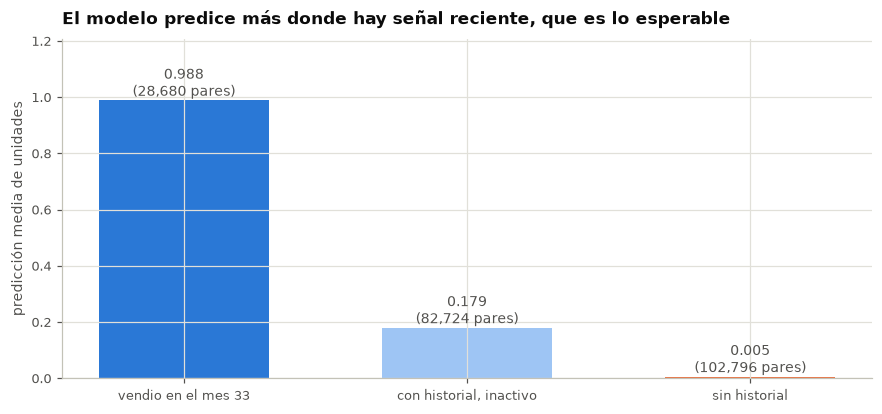

In [10]:
fig, ax = plt.subplots(figsize=(9.5, 4))
grupos = ["vendio en el mes 33", "con historial, inactivo", "sin historial"]
mascaras = [vivo_mes_33, con_historial & ~vivo_mes_33, ~con_historial]
colores = [AZUL, "#9ec5f4", NARANJA]

posiciones = np.arange(len(grupos))
medias = [predicciones[m].mean() for m in mascaras]
ax.bar(posiciones, medias, color=colores, width=0.6)
for i, (m, media) in enumerate(zip(mascaras, medias)):
    ax.annotate(f"{media:.3f}\n({m.sum():,} pares)", (i, media), ha="center",
                va="bottom", fontsize=9, color=TINTA2)
ax.set_xticks(posiciones)
ax.set_xticklabels(grupos)
ax.set_ylabel("predicción media de unidades")
ax.margins(y=0.22)
ax.set_title("El modelo predice más donde hay señal reciente, que es lo esperable")
fig.savefig(FIGURES_DIR / "05-2_prediccion_por_cobertura.png", dpi=150)
plt.show()

<a id="6"></a>
## 6. Archivo de envío

**Entregable 4 del proyecto.**

In [11]:
RUTA_ENVIO = PROCESSED_DATA_DIR / "submission.csv"
envio.to_csv(RUTA_ENVIO, index=False)

print(f"guardado en: {RUTA_ENVIO}")
print(f"tamanio    : {RUTA_ENVIO.stat().st_size / 1e6:.2f} MB")
print(f"filas      : {len(envio):,}")
display(envio.head())
display(envio.tail())

guardado en: C:\Users\dgarc\OneDrive\Escritorio\Maestria\4T_2026\Product_Mang\Clase_Cloud\predict_future_sales\data\processed\submission.csv
tamanio    : 5.15 MB
filas      : 214,200


,ID,item_cnt_month
0,0,0.460701
1,1,0.000000
2,2,0.736466
3,3,0.209978
4,4,0.010133


,ID,item_cnt_month
214195,214195,0.094844
214196,214196,0.000000
214197,214197,0.063041
214198,214198,0.000000
214199,214199,0.054688


In [12]:
# Ultima comprobacion: releer el archivo escrito y verificar que lo que esta en
# disco es lo que se queria escribir. Un error de formato al guardar seria
# invisible hasta el momento de enviarlo.
releido = pd.read_csv(RUTA_ENVIO)
assert len(releido) == len(test)
assert list(releido.columns) == ["ID", "item_cnt_month"]
assert releido["ID"].equals(test["ID"])
assert np.allclose(releido["item_cnt_month"], predicciones, atol=1e-6)
assert releido["item_cnt_month"].between(0, 20).all()
print("El archivo en disco coincide con las predicciones: OK")
print(f"\nresumen del envio:")
print(f"  media   : {releido.item_cnt_month.mean():.4f}")
print(f"  mediana : {releido.item_cnt_month.median():.4f}")
print(f"  ceros   : {(releido.item_cnt_month == 0).mean():.1%}")
print(f"  maximo  : {releido.item_cnt_month.max():.4f}")

El archivo en disco coincide con las predicciones: OK

resumen del envio:
  media   : 0.2039
  mediana : 0.0545
  ceros   : 22.2%
  maximo  : 20.0000


---

## Resumen

| | |
|---|---|
| **Entrada** | `data/raw/test.csv` crudo (214 200 filas, 3 columnas) |
| **Artefacto** | `models/pipeline_completo.pkl` |
| **Salida** | `data/processed/submission.csv` (`ID`, `item_cnt_month`) |
| **Ajustes realizados** | **Ninguno**: solo `predict` |
| **Verificaciones** | Forma · valores finitos · rango [0, 20] · alineación de ID · formato oficial · coherencia por cobertura · relectura del archivo |

### Lo que este notebook demuestra

Que el pipeline está **completo**. Fueron tres líneas de trabajo real —cargar el artefacto, leer
el CSV, llamar a `predict`— y todo lo demás son comprobaciones. No hubo que repetir ni un solo
cálculo de los notebooks anteriores, que es exactamente la propiedad que hace que un modelo se
pueda poner en producción.